In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

sales_path = "../data/raw/sales_train_evaluation.csv"
calendar_path = "../data/raw/calendar.csv"

# Select food products from Walmart store CA_1
selected_chunks = []

for chunk in pd.read_csv(sales_path, chunksize=250):
    selected = chunk[
        (chunk["store_id"] == "CA_1") &
        (chunk["cat_id"] == "FOODS")
    ]

    if not selected.empty:
        selected_chunks.append(selected)

food_sales = pd.concat(
    selected_chunks,
    ignore_index=True
)

# Daily sales columns
day_cols = [f"d_{i}" for i in range(1, 1942)]

# Select products using TRAINING data only
train_cols = [f"d_{i}" for i in range(1, 1774)]

food_sales["training_total"] = (
    food_sales[train_cols].sum(axis=1)
)

top_products = food_sales.nlargest(
    5, "training_total"
).copy()

print("Selected products:")
print(
    top_products[
        ["item_id", "training_total"]
    ].to_string(index=False)
)

# Convert wide daily sales data to long format
product_sales = top_products[
    ["item_id"] + day_cols
].melt(
    id_vars="item_id",
    var_name="d",
    value_name="units_sold"
)

# Attach dates
calendar = pd.read_csv(
    calendar_path,
    usecols=["d", "date"]
)

product_sales = product_sales.merge(
    calendar,
    on="d",
    how="left",
    validate="many_to_one"
)

product_sales["date"] = pd.to_datetime(
    product_sales["date"]
)

product_sales["day_number"] = (
    product_sales["d"]
    .str.extract(r"d_(\d+)")
    .astype(int)
)

product_sales = product_sales.sort_values(
    ["item_id", "day_number"]
).reset_index(drop=True)

# Save dataset for next notebook stages
product_sales.to_csv(
    "../data/selected_product_sales.csv",
    index=False
)

print("\nDataset shape:", product_sales.shape)
print(product_sales.head())


Selected products:
    item_id  training_total
FOODS_3_090          121612
FOODS_3_586           82671
FOODS_3_252           70281
FOODS_3_120           57224
FOODS_3_714           51437

Dataset shape: (9705, 5)
       item_id    d  units_sold       date  day_number
0  FOODS_3_090  d_1         107 2011-01-29           1
1  FOODS_3_090  d_2         182 2011-01-30           2
2  FOODS_3_090  d_3          47 2011-01-31           3
3  FOODS_3_090  d_4          47 2011-02-01           4
4  FOODS_3_090  d_5          62 2011-02-02           5


             average_daily_sales  max_daily_sales  zero_sales_rate
item_id                                                           
FOODS_3_090                66.39              599            24.16
FOODS_3_120                32.51              205            34.36
FOODS_3_252                39.18              147             0.31
FOODS_3_586                45.77              133             0.36
FOODS_3_714                28.14               93             0.36


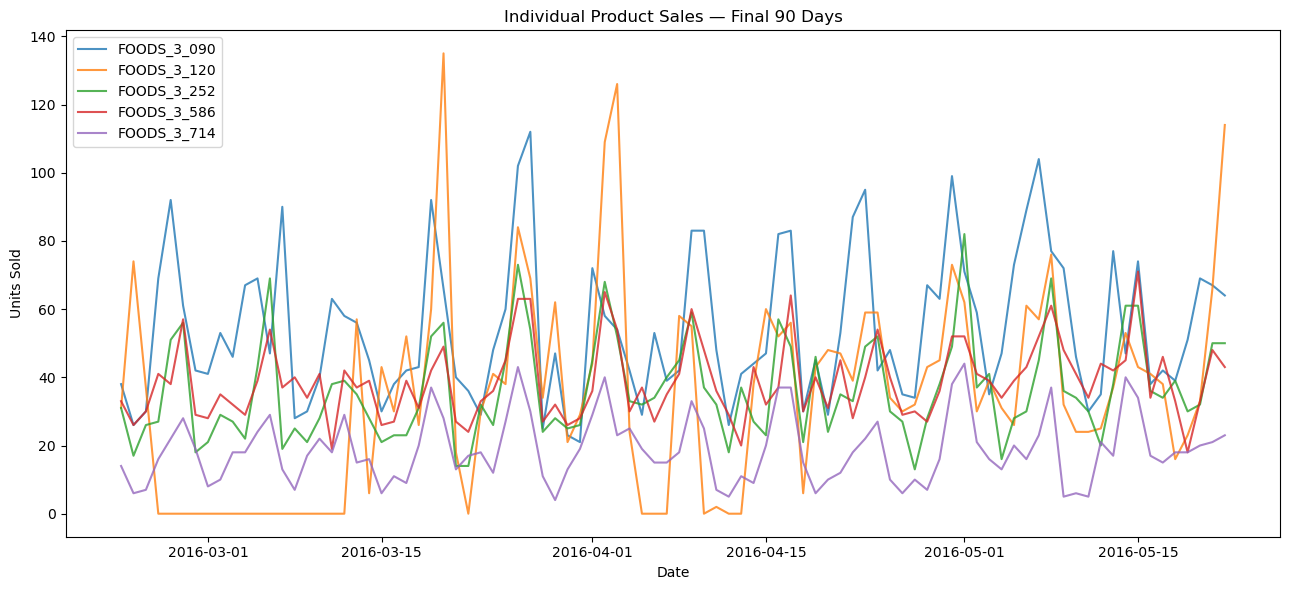

In [2]:

# Summarize demand characteristics
summary = product_sales.groupby("item_id").agg(
    average_daily_sales=("units_sold", "mean"),
    max_daily_sales=("units_sold", "max"),
    zero_sales_rate=(
        "units_sold",
        lambda x: (x == 0).mean() * 100
    )
)

print(summary.round(2).to_string())

# Visualize the last 90 days for each product
recent = product_sales[
    product_sales["day_number"] > 1851
]

plt.figure(figsize=(13, 6))

for product_id, group in recent.groupby("item_id"):
    plt.plot(
        group["date"],
        group["units_sold"],
        label=product_id,
        alpha=0.8
    )

plt.title("Individual Product Sales — Final 90 Days")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.legend()
plt.tight_layout()
plt.show()
